# 06 · Insights agrícolas: interpretação, limitações e hipóteses

**AgroGeo Analytics · Projeto 01**

> ⚠️ **Leia primeiro.** Este notebook não apresenta conclusões agronômicas: os dados são **sintéticos**. Ele demonstra *como raciocinar* a partir de sinais de satélite — transformar um sinal em **hipótese** a ser verificada em campo — e **quantifica as limitações** do método usando as propriedades geométricas dos talhões.

## Princípio central
> **NDVI/NDRE não diagnosticam doenças, pragas, deficiências nutricionais nem produtividade.** Eles medem *reflectância* da cena (folhas, solo, sombra, plantas daninhas entre as ruas). Diferenças de índice são **um indício para olhar o talhão**, nunca o diagnóstico.

In [1]:
import sys
from pathlib import Path
try:
    import agrogeo  # noqa: F401  (pacote instalado com `pip install -e .`)
except ModuleNotFoundError:  # kernel sem o pacote: usa o código-fonte do repositório
    _src = next(p / "src" for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "agrogeo").is_dir())
    sys.path.insert(0, str(_src))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from agrogeo import config, gis, indices, zonal, timeseries as ts_lib, maps
from agrogeo.config import DATA_SAMPLE, OUTPUTS, CRS_GEO, CRS_UTM22S

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
(OUTPUTS / "figures").mkdir(parents=True, exist_ok=True)
SYNTH_NOTE = "DADOS SINTÉTICOS — ilustrativo, não é medição"
tal = gpd.read_file(DATA_SAMPLE / "talhoes_sinteticos.geojson")
serie = pd.read_csv(DATA_SAMPLE / "serie_sintetica_ndvi_ndre.csv", parse_dates=["date"])
BASE = ("2021-01-01", "2022-12-31")
tal["area_ha"] = gis.area_ha(tal, CRS_UTM22S)

## 1. Quanto o pixel "enxerga" de cada talhão?

Um pixel Sentinel-2 de 10 m cobre 0,01 ha. Para talhões pequenos, a fração de pixels **inteiramente** dentro do talhão (interior) é limitada. Calculamos pixels aproximados (área / 100 m²) e a fração mantida após buffer interno de 10 m.

In [2]:
inter = gis.buffer_m(tal, -10, CRS_UTM22S)
lim = pd.DataFrame({
    "talhao_id": tal["talhao_id"], "area_ha": tal["area_ha"].round(2),
    "pixels_10m_aprox": (tal["area_ha"] * 100).round().astype(int),
    "pixels_interior_aprox": (gis.area_ha(inter, CRS_UTM22S) * 100).round().astype(int),
})
lim["interior_%"] = (100 * lim["pixels_interior_aprox"] / lim["pixels_10m_aprox"]).round(1)
lim["pixels_B5_20m_aprox"] = (lim["area_ha"] * 25).round().astype(int)
print("Interior médio:", lim["interior_%"].mean().round(1), "% | pixels de 20 m (B5/SCL) por talhão — mediana:", int(lim["pixels_B5_20m_aprox"].median()))
lim.head()

Interior médio: 86.2 % | pixels de 20 m (B5/SCL) por talhão — mediana: 203


,talhao_id,area_ha,pixels_10m_aprox,pixels_interior_aprox,interior_%,pixels_B5_20m_aprox
0,T01,8.30,830,717,86.4,208
1,T02,9.61,961,841,87.5,240
2,T03,9.70,970,848,87.4,242
3,T04,6.85,685,584,85.3,171
4,T05,10.93,1093,965,88.3,273


**Leitura:** nos talhões menores, uma parcela considerável dos pixels é de borda (mistura). Para **NDRE** (B5 a 20 m, reamostrado para 10 m) a mistura é ainda maior, e a **máscara SCL** também é 20 m. Talhões com poucas dezenas de pixels têm médias instáveis — **sinalize-os** em relatórios.

## 2. Culturas perenes: o que muda na leitura

| Aspecto | Cultura anual (soja, milho) | Café (perene) |
|---|---|---|
| Ciclo no NDVI | forte: solo → pico → senescência | atenuado: dossel presente o ano todo |
| Saturação do NDVI | só no pico | frequente em dossel denso (NDVI alto e "achatado") |
| Contribuição do solo/entrelinha | alta no início | permanente (plantas daninhas/cobertura, sombra das ruas) |
| Eventos de manejo | plantio/colheita | poda, esqueletamento, recepa, colheita, roçada |
| Ciclo produtivo | anual | **bienalidade** (anos de carga alta/baixa) |
| Idade | n/a | lavouras jovens têm dossel menor e NDVI menor |

Consequência: comparar um talhão com o **seu próprio histórico** e com **pares comparáveis** (mesma cultivar, idade e manejo) é mais informativo que olhar o valor absoluto.

## 3. Sinais → hipóteses → o que verificar em campo

Do notebook 04 (dados sintéticos), dois talhões se destacam por **construção**. Veja como transformamos um sinal em perguntas:

talhao_id
T08   -0.062
T03   -0.017
T02   -0.008


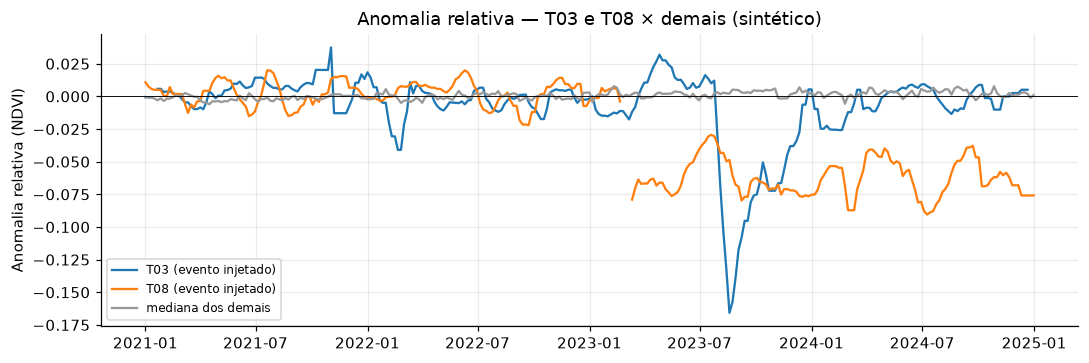

In [3]:
rel = ts_lib.relative_anomaly(serie, "ndvi", window_days=30, baseline=BASE)
pos = rel[rel.date >= "2023-04-01"].groupby("talhao_id")["anom_rel"].mean().sort_values()
print(pos.head(3).round(3).to_string())
fig, ax = plt.subplots(figsize=(10, 3.4))
for tid in ["T03", "T08"]:
    g = rel[rel.talhao_id == tid]; ax.plot(g["date"], g["anom_rel"], label=f"{tid} (evento injetado)")
ref = rel[~rel.talhao_id.isin(["T03", "T08"])].groupby("date")["anom_rel"].median()
ax.plot(ref.index, ref.values, color="#999", label="mediana dos demais"); ax.axhline(0, color="k", lw=.6)
ax.set(ylabel="Anomalia relativa (NDVI)", title="Anomalia relativa — T03 e T08 × demais (sintético)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "06_t03_t08.png"); plt.show()

**Como ler:** T03 cai e recupera (padrão *transitório*); T08 fica persistentemente abaixo (padrão *persistente*). A **forma** da curva ajuda a priorizar hipóteses — mas não escolhe uma.

| Padrão no sinal | Hipóteses agronômicas a considerar (não exclusivas) | O que verificar em campo / registros |
|---|---|---|
| Queda abrupta + recuperação gradual (meses) | poda/esqueletamento/recepa; roçada de entrelinha; granizo/geada; desfolha | caderno de campo (datas de manejo), visita ao talhão |
| Nível persistentemente menor que pares | lavoura mais jovem/velha; falhas de stand; solo/relevo; deficiência hídrica ou nutricional; manejo de plantas daninhas; ataque de pragas/doenças | análise de solo/folha, contagem de plantas, mapa de solos, monitoramento fitossanitário |
| Queda simultânea em muitos talhões | evento regional (seca, geada, nuvem residual, mudança de sensor/processamento) | dados meteorológicos, checagem da qualidade das imagens |
| Aumento súbito de NDVI | crescimento de plantas daninhas/cobertura, chuvas após seca | inspeção visual, histórico de roçada |
| Heterogeneidade alta dentro do talhão (CV alto) | variação de solo/relevo, falhas, manejo desigual, borda | mapa de pixels, amostragem georreferenciada |

> ⚠️ Nenhuma linha acima é um diagnóstico. São **hipóteses de trabalho** para orientar a inspeção, conforme a prática agronômica — a confirmação exige dados de campo e, quando cabe, análise laboratorial por profissional habilitado.

## 4. Limitações do método (checklist)

1. **Mistura de pixels** — veja a seção 1; use buffer interno e reporte nº de pixels.
2. **Resolução espacial** — 10 m (B4/B8), 20 m (B5/B8A/SCL); MapBiomas, 30 m (não resolve talhões pequenos nem entrelinhas).
3. **Sazonalidade** — compare mesma época (climatologia) ou use pares.
4. **Nuvens e sombras** — SCL imperfeita; lacunas longas no verão chuvoso.
5. **Perenes** — dossel contínuo, saturação do NDVI, ciclo bienal, efeito do solo/entrelinha.
6. **Variação sensor/processamento** — HARMONIZED reduz, não elimina, diferenças entre baselines.
7. **Geometria dos talhões** — erros de digitalização deslocam pixels; valide contra imagem recente.
8. **Autocorrelação** — observações sucessivas não são independentes; cuidado com testes estatísticos.
9. **Sem verdade de campo não há validação** — correlações com produtividade/sanidade exigem dados próprios.

## 5. MapBiomas: contexto de uso da terra

O MapBiomas Brasil (30 m, CC-BY 4.0 conforme o catálogo do Earth Engine) classifica uso e cobertura anualmente; a classe **46 = Café**. Usos típicos neste projeto: (a) conferir se o polígono do talhão cai majoritariamente em "Café"/"Lavoura Perene"; (b) estimar a área de café por município; (c) ver o histórico de conversão.

Execução (requer Earth Engine; **não executada no ambiente de desenvolvimento** por falta de credenciais):

```bash
python scripts/export_mapbiomas_stats.py --geojson data/sample/municipio_3538808.geojson --year 2023
```

Gera `data/processed/mapbiomas_area.csv` (área por classe). Antes de usar, confirme no catálogo as propriedades `collection_id`/`version` e a legenda da coleção vigente — elas mudam entre coleções.

In [4]:
# Se o CSV do MapBiomas existir (rodado por você), resumimos; caso contrário, apenas avisamos.
p = config.DATA_PROCESSED / "mapbiomas_area.csv"
if p.exists():
    mb = pd.read_csv(p); display(mb.groupby("classe_nome")["area_ha"].sum().sort_values(ascending=False).round(0))
else:
    print("mapbiomas_area.csv não encontrado: etapa MapBiomas não executada neste ambiente.")

mapbiomas_area.csv não encontrado: etapa MapBiomas não executada neste ambiente.


## 6. Roteiro para aplicar a dados reais
1. Digitalize/importe os **talhões reais** (GeoJSON, EPSG:4326, coluna `talhao_id`), validando geometrias (notebook 01).
2. Configure `.env` (`EE_PROJECT`, `AGROGEO_USE_EE=1`) e autentique no Earth Engine.
3. Rode `scripts/export_s2_timeseries.py` com seu GeoJSON e use o CSV nos notebooks 03–05.
4. Defina o **período-base** sem eventos conhecidos e registre o **caderno de campo** (poda, colheita, adubação, irrigação).
5. Cruze anomalias com o caderno e com visitas; **registre** quais hipóteses foram confirmadas ou refutadas.
6. Só então discuta decisões de manejo, com um agrônomo.

## 7. Questões para aprofundamento
- Como o NDVI de um talhão de café com **entrelinha roçada vs. com mato alto** difere, e como isso confunde a anomalia?
- O que muda ao usar **mediana mensal** vs. **máximo mensal (MVC)**?
- Como estimar a incerteza da média zonal quando há poucos pixels?
- Que variáveis externas (precipitação, temperatura, balanço hídrico) você adicionaria para separar "clima" de "manejo"?